# M203 - Análisis Exploratorio de Datos (EDA)

> Módulo II - Data Science
>
> Tema 3: Análisis exploratorio de datos (EDA)

Contenido:

1. Naturaleza de los datos: Cuantitativo/Cualitativo
2. Espacio de Análisis y Caracterización
3. Análisis individual de características
4. Análisis entre grupos de características
5. Reporte: Respuestas y su contraste

## Introducción

De aproximadamente 2,500 pasajeros del Titanic (~1910), se cuentan con 891 registros reales, codificados en una tabla como:

* **Passanger Id** - Id del pasajero (excluído)
* **Survived** - 1 o 0 si sobrevive
* **Pclass** - 1ra, 2da o 3ra
* **Name** - Nombre del pasajero (excluído)
* **Age** - Edad del pasajero (datos malformados y 20% perdidos)
* **Sex** - Sexo del pasajero (hombre o mujer)
* **SibSp** - Cantidad de familia horizontal (hermanos y cónyuges)
* **Parch** - Cantidad de familia vertical (padres e hijos)
* **Fare** - Tarifa (valores atípicos)
* **Ticket** - Ticket del pasajero (excluído)
* **Cabin** - El número de cabina (o nulo)
* **Embarked** - El puerto de embarcación

In [4]:
import pandas as pd
import numpy as np
from matplotlib import pyplot
import seaborn

In [6]:
titanic = pd.read_csv("../conjuntos/titanic.csv")

titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 1. Caracterización

> Cuantitativas

* $C_1$ - Edad (*Age*)
* $C_2$ - Familia Horizontal (*SibSp*)
* $C_3$ - Familia Vertical (*Parch*)
* $C_4$ - Tarifa (*Fare*)

> Cualitativas

* $C_5$ - Supervivencia (*Survived*)
* $C_6$ - Clase (*Pclass*)
* $C_7$ - Sexo (*Sex*)
* $C_8$ - Cabina (*Cabin*)
* $C_9$ - Embarcación (*Embarked*)

In [26]:
c1 = titanic["Age"]
c1[c1 < 1] = c1[c1 < 1] * 100 # Corregir edades malformadas (en decimales)
c2 = titanic["SibSp"]
c3 = titanic["Parch"]
c4 = titanic["Fare"]
c5 = titanic["Survived"].map({0: "No", 1: "Yes"}) # Cambiamos 0/1 por "No"/"Yes"
c6 = titanic["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"}) # Cambiamos 1/2/3 por "1st"/"2nd"/"3rd"
c7 = titanic["Sex"] # "male"/"female"
c8 = titanic["Cabin"].isna().map({True: "no", False: "yes"}) # Transformamos a lógico es nulo, luego a si tiene cabina "yes"/"no"
c9 = titanic["Embarked"] # "Q"/"S"/"C" (irlanda (Q - Quenstown), inglaterra (S - Southampton) y francia (C - Cherbug))

In [38]:
#Edades
c1.describe()

count    714.000000
mean      30.415966
std       14.953362
min        1.000000
25%       21.000000
50%       28.750000
75%       39.000000
max       92.000000
Name: Age, dtype: float64

<Axes: xlabel='Age', ylabel='Density'>

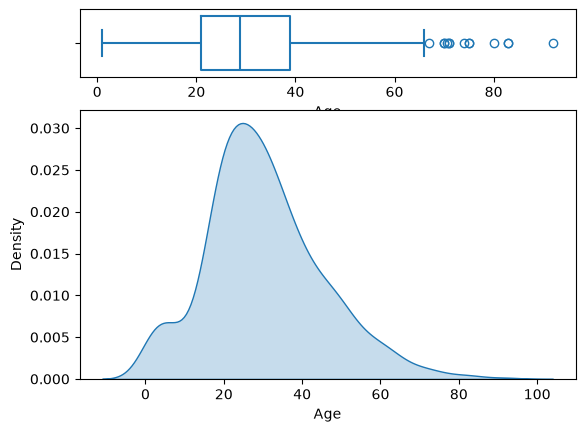

In [27]:
figure, axes = pyplot.subplots(2, 1, height_ratios = (1, 4)) # Los ratios son para darle más tamaño a un gráfico que a otro

seaborn.boxplot(x=c1, ax=axes[0], fill=False)
seaborn.kdeplot(x=c1, ax=axes[1], fill=True)

<Axes: xlabel='Age', ylabel='Density'>

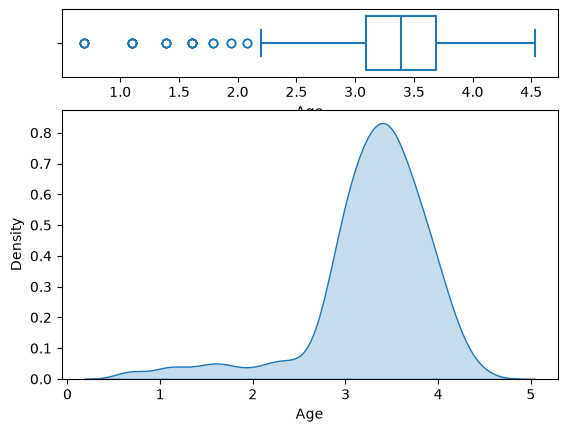

In [44]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=np.log1p(c1), ax=axes[0], fill=False)
seaborn.kdeplot(x=np.log1p(c1), ax=axes[1], fill=True)

In [39]:
#Familia Horizontal
c2.describe()

count    891.000000
mean       0.523008
std        1.102743
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        8.000000
Name: SibSp, dtype: float64

<Axes: xlabel='SibSp', ylabel='Density'>

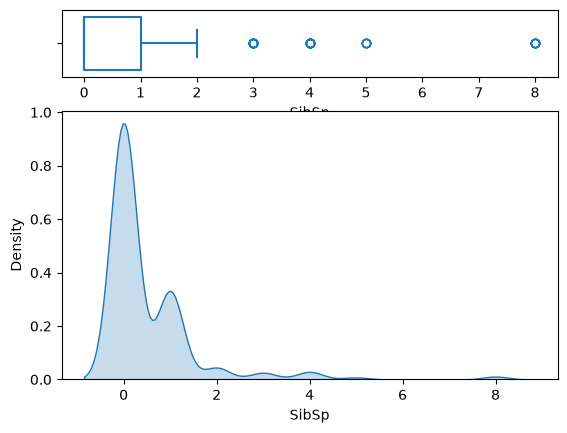

In [40]:
figure, axes = pyplot.subplots(2, 1, height_ratios = (1, 4)) # Los ratios son para darle más tamaño a un gráfico que a otro

seaborn.boxplot(x=c2, ax=axes[0], fill=False)
seaborn.kdeplot(x=c2, ax=axes[1], fill=True)

In [41]:
#Familia Vertical
c3.describe()

count    891.000000
mean       0.381594
std        0.806057
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        6.000000
Name: Parch, dtype: float64

<Axes: xlabel='Parch', ylabel='Density'>

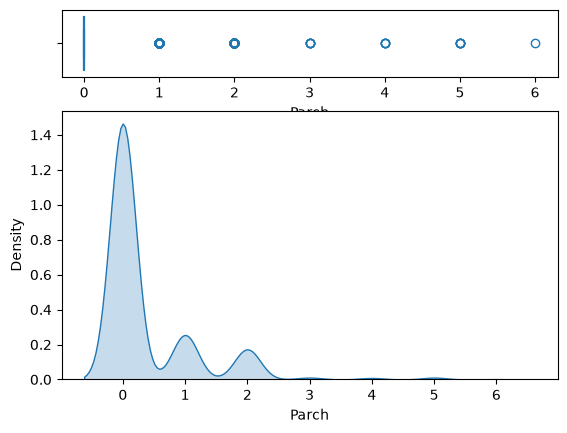

In [42]:
figure, axes = pyplot.subplots(2, 1, height_ratios = (1, 4)) # Los ratios son para darle más tamaño a un gráfico que a otro

seaborn.boxplot(x=c3, ax=axes[0], fill=False)
seaborn.kdeplot(x=c3, ax=axes[1], fill=True)

<Axes: xlabel='Survived', ylabel='Density'>

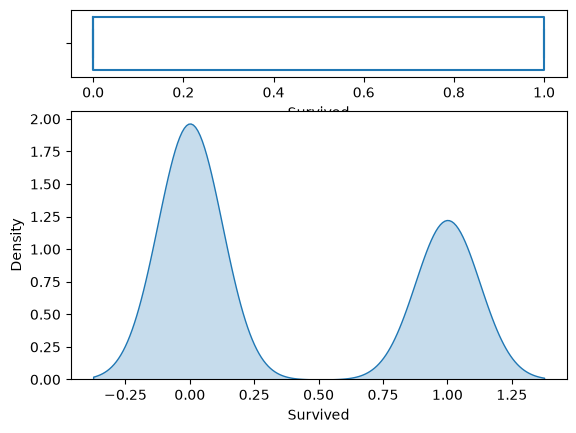

In [47]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=titanic["Survived"], ax=axes[0], fill=False)
seaborn.kdeplot(x=titanic["Survived"], ax=axes[1], fill=True)

In [13]:
c4.describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [14]:
c5.describe()

count     891
unique      2
top        No
freq      549
Name: Survived, dtype: object

In [15]:
c6.describe()

count     891
unique      3
top       3rd
freq      491
Name: Pclass, dtype: object

In [16]:
c7.describe()

count      891
unique       2
top       male
freq       577
Name: Sex, dtype: object

In [17]:
c8.describe()

count     891
unique      2
top        no
freq      687
Name: Cabin, dtype: object

In [18]:
c9.describe()

count     889
unique      3
top         S
freq      644
Name: Embarked, dtype: object